In [1]:
import numpy as np
import netCDF4 as nc
import matplotlib.pyplot as plt
import scipy as scp

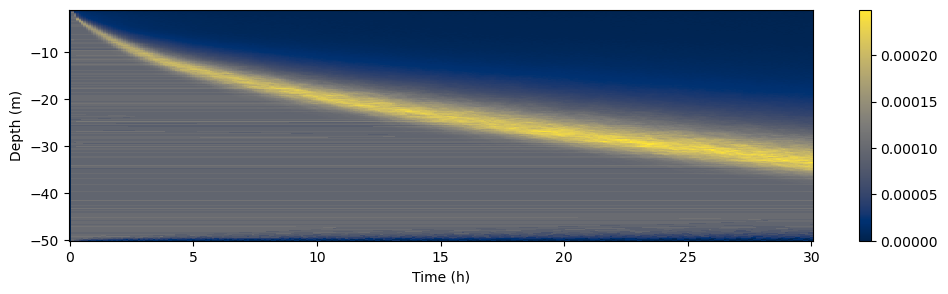

In [ ]:
OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/1_Kato_Phillips/output/'
OUTPUT_FILE = 'K-P_tke_dt360_nz512_ne500.nc'

filename = OUTPUT_FOLDER + OUTPUT_FILE
with nc.Dataset(filename) as data:    
    z_c = data['zc'][:]
    z_w = data['zw'][:]
    t_s = data['time'][:]
    t = data['time'][:] / 3600
    
    temp  = data['temp_mean'][:]
    N2    = data['N2_mean'][:]
    mld_m = data['mld_mean'][:]
    mld_v = data['mld_var'][:]
    
t0, z0 = np.meshgrid(t, z_w)

plt.figure(figsize = (12, 3))
plt.pcolormesh(t0, z0, N2.T, cmap = 'cividis')
plt.xlabel('Time (h)')
plt.ylabel('Depth (m)')
plt.colorbar()

# Kato - Phillips Experiment 

In this idealized configuration, the mixed‑layer depth is expected to follow an empirical deepening law of the form

$$\mathrm{MLD}(t) = 1.05\,\frac{u_*}{\sqrt{N}}\,\sqrt{t - t_0}$$

Reliable for about 30h

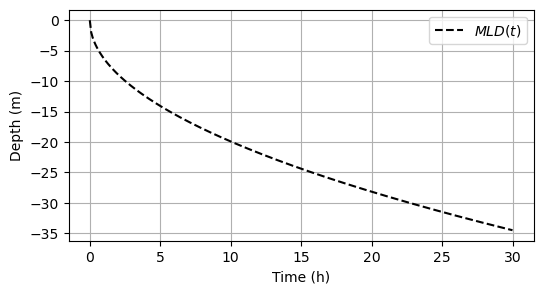

In [3]:
# Reference value
def get_ref_MLD(t):
    N2 = np.sqrt(1e-4)
    ust = 0.01
    return 1.05 * ust/np.sqrt(N2) * np.sqrt(t)

MLD_REF = get_ref_MLD(t_s)

plt.figure(figsize = (6, 3))
plt.plot(t_s/3600, -MLD_REF, 'k--', label = r'$MLD(t)$')
plt.xlabel('Time (h)')
plt.ylabel('Depth (m)')
plt.grid()
plt.legend()

## Everything compared

In [4]:
DTS = [36, 360, 3600]
NZS = [512, 256]#, 128]
NENS = 500

CLOSURES = [
    ('k-kl',      r'$k\text{-}kl$'),
    ('k-epsilon', r'$k\text{-}\epsilon$'),
    ('k-omega',   r'$k\text{-}\omega$'),
    ('gen',       r'$gen$'),
    ('kpp',       r'$KPP$'),
    ('tke',       r'$TKE$')
]

def get_mld_timeserie(file, cut = 0):
    with nc.Dataset(OUTPUT_FOLDER + file) as data:
        t     = data['time'][cut:] / 3600
        mld_m = data['mld_mean'][cut:]
        mld_v = data['mld_var'][cut:]
    return t, mld_m, mld_v

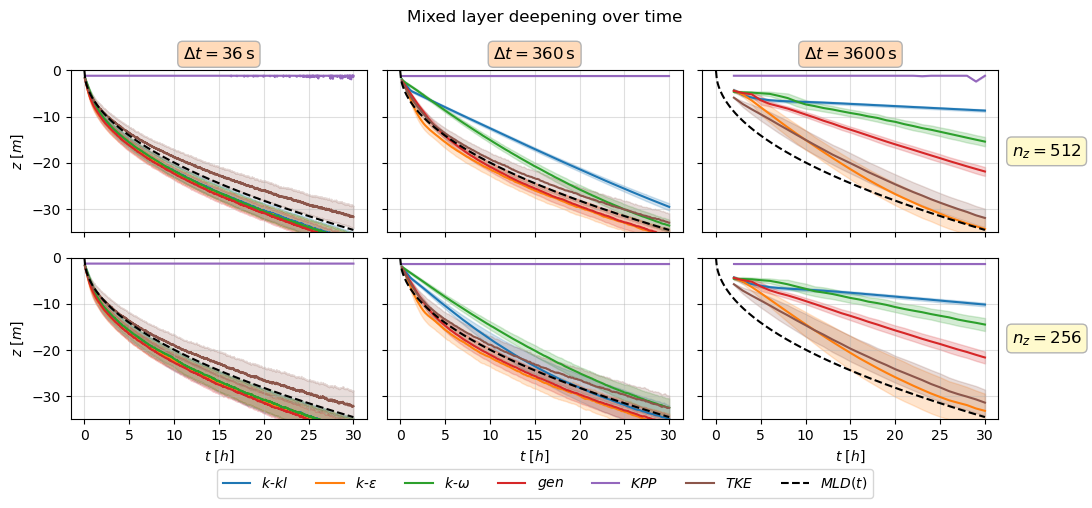

In [5]:
fig, axes = plt.subplots(len(NZS), len(DTS), figsize=(int(len(DTS)*3 + 2), int(len(NZS)*2 + 1)), sharex=True, sharey=True)
fig.suptitle(r'Mixed layer deepening over time')

for i, nz in enumerate(NZS):
    for j, dt in enumerate(DTS):
        ax = axes[i, j]

        for key, label in CLOSURES:
            if dt == 36:
                t, mld_m, mld_v = get_mld_timeserie(f'K-P_{key}_dt{dt}_nz{nz}_ne{NENS}.nc', cut = 6)
            else:
                t, mld_m, mld_v = get_mld_timeserie(f'K-P_{key}_dt{dt}_nz{nz}_ne{NENS}.nc', cut = 2)
            
            std = mld_v ** 0.5
            line, = ax.plot(t, -mld_m, label=label)
            ax.fill_between(t, -(mld_m - std), -(mld_m + std), alpha=0.2, color=line.get_color())

        ax.plot(t_s/3600, -MLD_REF, 'k--', label=r'$MLD(t)$')
        ax.set_ylim(-35, 0)
        ax.grid(True, alpha=0.4)
        if j == 0:
            ax.set_ylabel(r'$z$ [$m$]')
        if i == len(NZS)-1:
            ax.set_xlabel(r'$t$ [$h$]')

for j, dt in enumerate(DTS):
    axes[0, j].annotate(rf'$\Delta t = {dt}\,$s', xy=(0.5, 1.1),
                         xycoords='axes fraction', 
                         va='center', ha='center', fontsize=12,
                         bbox=dict(boxstyle='round', facecolor='peachpuff',
                                   edgecolor='0.7'))

for i, nz in enumerate(NZS):
    axes[i, -1].annotate(rf'$n_z = {nz}$', xy=(1.045, 0.5),
                         xycoords='axes fraction', 
                         va='center', ha='left', fontsize=12,
                         bbox=dict(boxstyle='round', facecolor='lemonchiffon',
                                   edgecolor='0.7'))

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=[0, 0.04, 1, 1])

## Forecast score

In [6]:
def forecast_score(time, var_m, var_v, nr):
    # Ref MLD
    ref = get_ref_MLD(time * 3600)
    
    # Forecast score    
    MSE = (var_m - ref)**2
    VAR = (nr + 1) / (nr - 1) * var_v
    EPS = np.abs(MSE-VAR)
    
    # Coeffs for filtering
    dt = time[1] - time[0] # hours
    fs = 5./(dt) # samp. freq.
    fc = 1. # cutoff freq. (1/hours)
    wid = fc/(fs/2)
    num_filt, denom_filt = scp.signal.butter(5, wid, 'low') # 5th order Butterworth
    
    EPS = scp.signal.filtfilt(num_filt, denom_filt, EPS)
    return time, EPS

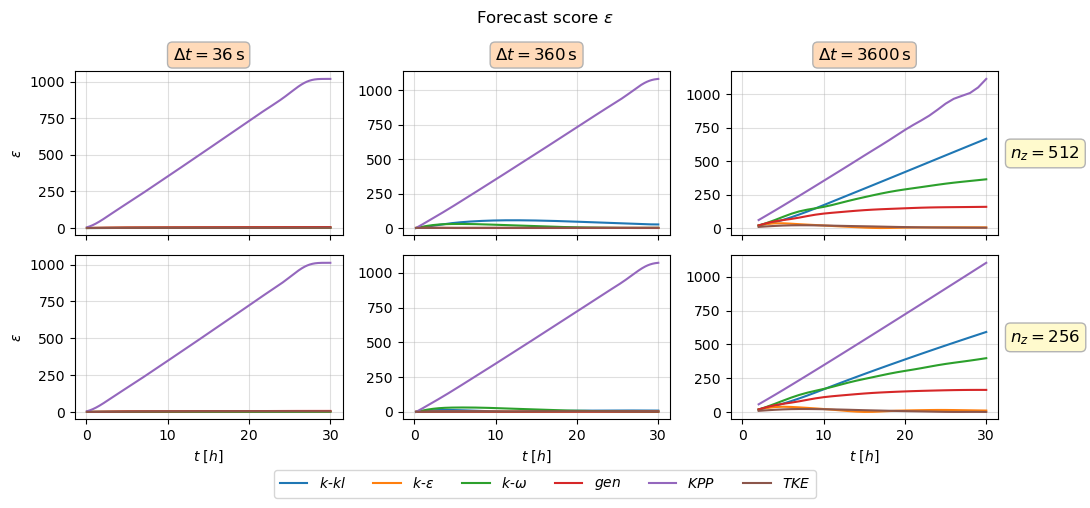

In [7]:
fig, axes = plt.subplots(len(NZS), len(DTS), figsize=(int(len(DTS)*3 + 2), int(len(NZS)*2 + 1)), sharex=True)
fig.suptitle(r'Forecast score $\varepsilon$')

for i, nz in enumerate(NZS):
    for j, dt in enumerate(DTS):
        ax = axes[i, j]
        
        for key, label in CLOSURES:
            if dt == 36:
                t, mld_m, mld_v = get_mld_timeserie(f'K-P_{key}_dt{dt}_nz{nz}_ne{NENS}.nc', cut = 6)
            else:
                t, mld_m, mld_v = get_mld_timeserie(f'K-P_{key}_dt{dt}_nz{nz}_ne{NENS}.nc', cut = 2)
                
            t, eps = forecast_score(t, mld_m, mld_v, NENS)
            ax.plot(t, eps, label = label)
        
        ax.grid(True, alpha=0.4)
        
        if j == 0:
            ax.set_ylabel(r'$\varepsilon$')
            
        if i == len(NZS)-1:
            ax.set_xlabel(r'$t$ [$h$]')
        
for j, dt in enumerate(DTS):
    axes[0, j].annotate(rf'$\Delta t = {dt}\,$s', xy=(0.5, 1.1),
                         xycoords='axes fraction', 
                         va='center', ha='center', fontsize=12,
                         bbox=dict(boxstyle='round', facecolor='peachpuff',
                                   edgecolor='0.7'))

for i, nz in enumerate(NZS):
    axes[i, -1].annotate(rf'$n_z = {nz}$', xy=(1.045, 0.5),
                         xycoords='axes fraction', 
                         va='center', ha='left', fontsize=12,
                         bbox=dict(boxstyle='round', facecolor='lemonchiffon',
                                   edgecolor='0.7'))

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=[0, 0.04, 1, 1])

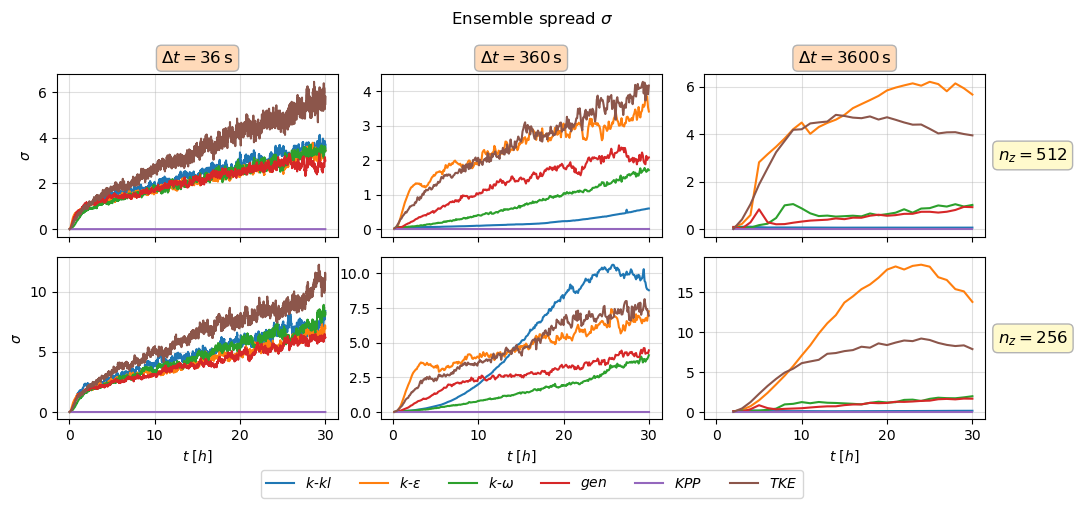

In [8]:
fig, axes = plt.subplots(len(NZS), len(DTS), figsize=(int(len(DTS)*3 + 2), int(len(NZS)*2 + 1)), sharex=True)
fig.suptitle(r'Ensemble spread $\sigma$')

for i, nz in enumerate(NZS):
    for j, dt in enumerate(DTS):
        ax = axes[i, j]
        
        for key, label in CLOSURES:
            if dt == 36:
                t, mld_m, mld_v = get_mld_timeserie(f'K-P_{key}_dt{dt}_nz{nz}_ne{NENS}.nc', cut = 6)
            else:
                t, mld_m, mld_v = get_mld_timeserie(f'K-P_{key}_dt{dt}_nz{nz}_ne{NENS}.nc', cut = 2)
                
            ax.plot(t, mld_v, label = label)
        
        ax.grid(True, alpha=0.4)
        
        if j == 0:
            ax.set_ylabel(r'$\sigma$')
            
        if i == len(NZS)-1:
            ax.set_xlabel(r'$t$ [$h$]')
        
for j, dt in enumerate(DTS):
    axes[0, j].annotate(rf'$\Delta t = {dt}\,$s', xy=(0.5, 1.1),
                         xycoords='axes fraction', 
                         va='center', ha='center', fontsize=12,
                         bbox=dict(boxstyle='round', facecolor='peachpuff',
                                   edgecolor='0.7'))

for i, nz in enumerate(NZS):
    axes[i, -1].annotate(rf'$n_z = {nz}$', xy=(1.045, 0.5),
                         xycoords='axes fraction', 
                         va='center', ha='left', fontsize=12,
                         bbox=dict(boxstyle='round', facecolor='lemonchiffon',
                                   edgecolor='0.7'))

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=[0, 0.04, 1, 1])